# Churn Analysis and Customer Intelligence

### 1. Import Libraries

In [1]:
# Import libraries for data analysis and visualization

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

### 2. Importing Database and Data

In [2]:
#Importing database / data

#Connect to SQLite database 
conn = sqlite3.connect('customer_churn.db')

#sql query to get all table names
sql_query = """
        SELECT name
        FROM sqlite_master
        WHERE type='table'
"""

#reading sql query in pandas
tables = pd.read_sql(sql_query, conn)

#create dataframe for each table 
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}", conn) #read table into dataframe
    globals()[f"df_{table_name}"] = df                    #create dynamic dataframe name
    print(f"Created dataframe: df_{table_name}")
    
#close connection
conn.close()    

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [3]:
# Print table names and column names
conn = sqlite3.connect('customer_churn.db')

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    # Get column information
    columns_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(columns_query, conn)
    print("Columns:")
    print(columns['name'].tolist())

# Close connection
conn.close()


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


### 3. Data Cleaning

In [4]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [5]:
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,NaN,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,NaN,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,NaN,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,NaN,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,NaN,None


In [6]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 2.5+ KB


In [7]:
#3.a. Renaming column Name

df_db_customer.rename(columns = {'name' : 'customer name'}, inplace= True)
df_db_customer

,customerid,customer name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00,NaN,None
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00,NaN,None
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00,NaN,None
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00,NaN,None
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00,NaN,None


In [8]:
#3.b. Drop columns - interest and pin code

df_db_customer.drop(columns=['interests', 'pincode'], inplace=True)
df_db_customer

,customerid,customer name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00


In [9]:
#3.c. change data type - dob

df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

In [10]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     21 non-null     str           
 1   customer name  21 non-null     str           
 2   country        18 non-null     str           
 3   state          21 non-null     str           
 4   gender         21 non-null     str           
 5   dob            21 non-null     datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 1.8 KB


In [11]:
#3.d. data standardization - gender

df_db_customer['gender'].unique()

<ArrowStringArray>
['Male', 'Female', 'Women', 'Men']
Length: 4, dtype: str

In [12]:
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men' : 'Male', 'Women' : 'Female'})

In [13]:
df_db_customer['gender'].unique()

<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str

In [14]:
#3.e. Fix missing values - country 

df_db_customer[df_db_customer['country'].isna()]

,customerid,customer name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [15]:
#Country and State - Unique value Pair

#creating state - country map from non-null rows
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

#Fill the missing country using state
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [16]:
#no null value in country col
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer name,country,state,gender,dob


In [17]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [18]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 3.1 KB


In [19]:
# change data type to date - subscription_start_date , renewal_date, cancellation_date
date_col = ['subscription_start_date', 'renewal_date', 'cancellation_date']

df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 2.7 KB


In [20]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [21]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 895.0+ bytes


In [22]:
#drop columns
df_db_support.drop(columns=['col_1', 'comment'], inplace=True)

In [23]:
#change data type to date - complaint date
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])

In [24]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 519.0 bytes


### 4. Feature Engineering and Data Analysis

In [25]:
# Correct spelling in subscription_type

df_db_subscription['subscription_type'] = (
    df_db_subscription['subscription_type']
    .replace('Refferal', 'Referral')
)

df_db_subscription['subscription_type'].value_counts()

subscription_type
Organic     9
Referral    6
Paid        6
Name: count, dtype: int64

In [26]:
#create a new col using existing column - churn Flag
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(), 1, 0)

In [27]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Referral,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Referral,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [28]:
df_db_support['customerid'].value_counts()

customerid
0003-MKNFE    2
0022-TCJCI    2
0013-EXCHZ    1
0013-MHZWF    1
0013-SMEOE    1
0017-IUDMW    1
0019-EFAEP    1
Name: count, dtype: int64

In [29]:
# Summarize support data by customer
df_support_summary = (df_db_support
    .groupby('customerid')
    .agg(
        support_count = ('customerid', 'size'),
        latest_complaint_date = ('complaint_date', 'max')
    )
    .reset_index()
)

In [30]:
df_support_summary.head()

,customerid,support_count,latest_complaint_date
0,0003-MKNFE,2,2024-08-28
1,0013-EXCHZ,1,2024-01-20
2,0013-MHZWF,1,2025-03-18
3,0013-SMEOE,1,2024-11-01
4,0017-IUDMW,1,2024-04-10


In [31]:
#first fix support table duplicates then merge
df = (df_db_subscription
    .merge(df_db_customer, on = 'customerid', how = 'left')
    .merge(df_support_summary, on = 'customerid', how = 'left')
)

In [32]:
len(df_db_subscription), len(df)

(21, 21)

In [33]:
df_db_subscription.shape

(21, 12)

In [34]:
df.shape

(21, 19)

In [35]:
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,customer name,country,state,gender,dob,support_count,latest_complaint_date
0,0002-ORFBO,2021-03-15,Referral,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0,keshav,India,Maharashtra,Male,1982-04-12,NaN,NaT
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2.0,2024-08-28
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0,lalita,India,Delhi,Female,1978-02-15,NaN,NaT
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0,mohan,India,Nagaland,Male,2001-08-30,NaN,NaT
4,0013-EXCHZ,2023-01-05,Referral,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1,mira,India,Delhi,Female,1990-05-05,1.0,2024-01-20


In [36]:
print('df_db_subscription unique value:', df_db_subscription['customerid'].nunique())
print('df_db_customer unique value:', df_db_customer['customerid'].nunique())
print('df_db_support unique value:', df_db_support['customerid'].nunique())
print('df_db_support all value:', df_db_support['customerid'].size)

df_db_subscription unique value: 21
df_db_customer unique value: 21
df_db_support unique value: 7
df_db_support all value: 9


In [37]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [38]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [39]:
df_db_support

,customerid,complaint_date,escalations,csat_score,complaint_count
0,0003-MKNFE,2024-08-28,N,60,2
1,0003-MKNFE,2024-08-28,Y,10,2
2,0013-EXCHZ,2024-01-20,Y,20,1
3,0013-MHZWF,2025-03-18,N,90,1
4,0013-SMEOE,2024-11-01,N,30,1
5,0017-IUDMW,2024-04-10,Y,25,1
6,0019-EFAEP,2024-09-27,Y,30,1
7,0022-TCJCI,2024-09-13,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2


In [40]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep = 'last')

In [41]:
df_db_support['customerid'].size

7

In [42]:
#merge  df
df = (df_db_subscription
    .merge(df_db_customer, on = 'customerid', how = 'left')
    .merge(df_db_support, on = 'customerid', how = 'left') )

In [43]:
df.shape

(21, 21)

### 5. Exporting the Dataframe

In [44]:
#export dataframe to csv file
df.to_csv('exported_churn_data.csv', index=False)

### 6. Data Analysis

#### 6.1. Churn Rate

In [45]:
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = ", round(churn_rate, 2), "%")

Churn Rate =  28.57 %


#### 6.2. Retention Rate

In [46]:
retention_rate = 100 - churn_rate
print("Retention Rate = ", round(retention_rate, 2), "%")

Retention Rate =  71.43 %


#### 6.3. Churn by Plan Type

In [47]:
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


#### 6.4. State-wise Churn Rate, Monthly Charges & Customer Count

In [48]:
churn_by_state = df.groupby('state').agg(
    churn_rate=('churn_flag', 'mean'),
    total_revenue=('monthly_charges', 'sum'),
    total_users=('customerid', 'nunique')
).reset_index()

churn_by_state['churn_rate'] = (churn_by_state['churn_rate'] * 100).round(2)

print(churn_by_state)

           state  churn_rate  total_revenue  total_users
0          Delhi       25.00          52.96            4
1      Karnataka      100.00          20.98            2
2      Kathmandu        0.00          20.98            2
3    Maharashtra        0.00          50.97            3
4      Meghalaya       66.67          42.97            3
5       Nagaland        0.00          22.99            1
6      Rajasthan        0.00          36.98            2
7      Telangana       50.00          30.98            2
8  Uttar Pradesh        0.00         115.98            2


#### 6.5. Churn by Subscription Type, Monthly Charges & Customer Count

In [49]:
churn_by_subscription = df.groupby('subscription_type').agg(
    churn_rate=('churn_flag', 'mean'),
    total_revenue=('monthly_charges', 'sum'),
    total_users=('customerid', 'nunique')
).reset_index()

churn_by_subscription['churn_rate'] = (churn_by_subscription['churn_rate'] * 100).round(2)

print(churn_by_subscription)

  subscription_type  churn_rate  total_revenue  total_users
0           Organic        0.00         145.91            9
1              Paid       16.67         174.94            6
2          Referral       83.33          74.94            6


#### 6.6.  ARPU - Average Revenue Per User

In [50]:
arpu = df['monthly_charges'].mean()
print('ARPU = ', round(arpu, 2))

ARPU =  18.85


#### 6.7. Churn by Customer Age

In [51]:
churn_by_age = df.groupby(
    pd.cut(
        (pd.Timestamp.today() - df['dob']).dt.days // 365.25,
        bins=[0, 18, 30, 45, 60, 100],
        labels=['Under 18', '18-30', '31-45', '46-60', '60+']
    )
).agg(
    churn_rate=('churn_flag', 'mean'),
    total_users=('customerid', 'nunique')
).reset_index()

churn_by_age['churn_rate'] = (churn_by_age['churn_rate'] * 100).round(2)

print(churn_by_age)

     dob  churn_rate  total_users
0  18-30       16.67            6
1  31-45       36.36           11
2  46-60       25.00            4


#### 6.8. Average Customer Tenure

In [52]:
#Count of days users has used our service : cancellation date else current date
today = pd.Timestamp.today()

df['tenure_days'] = np.where(
    df['cancellation_date'].notna(), 

   (df['cancellation_date'] - df['subscription_start_date']).dt.days, 

    (today - df['subscription_start_date']).dt.days
    
)
avg_tenure = df['tenure_days'].mean()
print("Avg Tenure(Days) = ", round(avg_tenure),0)

Avg Tenure(Days) =  1570 0


#### 6.9. Revenue at risk - revenue lost from churned users

In [53]:
revenue_at_risk = df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Revenue_at_risk(Rs 'K')=", revenue_at_risk)

Revenue_at_risk(Rs 'K')= 73.94


#### 6.10.Escalation Rate

In [54]:
escalation_rate = (df['escalations']=='Y').mean()*100
print("Escalation Rate = ", round(escalation_rate, 2), "%")

Escalation Rate =  19.05 %


#### 6.11. Avg Complaint Rate per User

In [55]:
avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print("Average Complaints Per User = ", round(avg_complaints, 2))

Average Complaints Per User =  0.43


#### 6.12. Correlation Escalation vs Churn 

In [56]:
#encoding string to int type
df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0) 
corr_df = df[['escalations', 'churn_flag']].dropna()

correlation = corr_df['escalations'].corr(df['churn_flag'])
print("Correlation between esclation vs churn is = ", round(correlation,2))

Correlation between esclation vs churn is =  0.77


#### 6.13. churn Risk 

In [57]:
#create a column using existing column
conditions = [
    (df['churn_score'] < 50),
    (df['churn_score'] >= 50) & (df['churn_score'] < 70),
    (df['churn_score'] >= 70)

]

choices = ['low', 'med', 'high']

df['churn_risk'] = np.select(conditions, choices, default ='unknown')

print(df[['churn_score', 'churn_risk']].head())

   churn_score churn_risk
0           12        low
1           91       high
2           34        low
3            8        low
4           88       high


#### 6.14. Actual Churn Rate by Churn Risk Category

In [58]:
# Actual churn rate by churn risk category

churn_by_risk = (
    df.groupby('churn_risk')['churn_flag']
    .mean()
    .mul(100)
    .round(2)
    .reset_index(name='actual_churn_rate_pct')
)

print(churn_by_risk)

  churn_risk  actual_churn_rate_pct
0       high                  100.0
1        low                    0.0
2        med                    0.0


### 7. Data Visualization using Matplotlib 

In [59]:
# Creating a copy for visualization
df_visual = df.copy()

#### 7.1 Monthly Churn Trend (Time Series KPI)

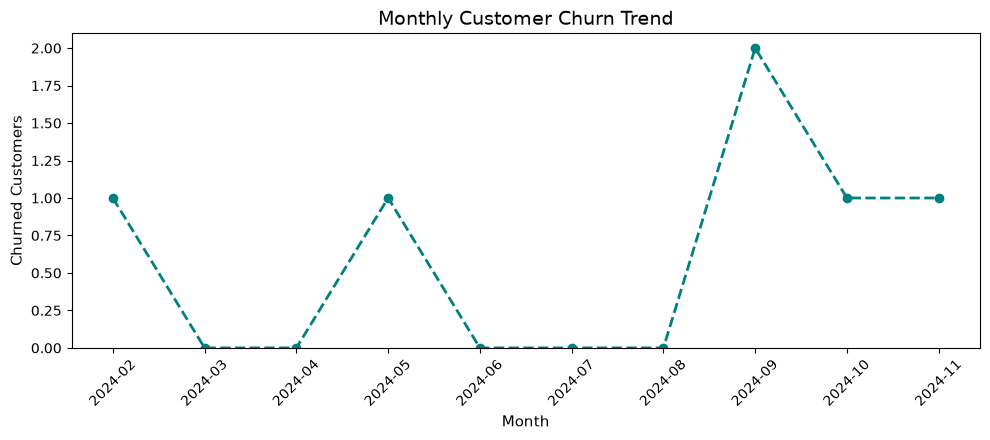

In [60]:
# Calculate monthly churned customers

df_visual['cancellation_date'] = pd.to_datetime(
    df_visual['cancellation_date'],
    errors='coerce'
)

churned_customers = df_visual[
    (df_visual['churn_flag'] == 1) &
    (df_visual['cancellation_date'].notna())
]

churn_trend = (
    churned_customers
    .groupby(
        churned_customers['cancellation_date'].dt.to_period('M')
    )['customerid']
    .nunique()
    .sort_index()
)

# Include months with zero churn
all_months = pd.period_range(
    start=churn_trend.index.min(),
    end=churn_trend.index.max(),
    freq='M'
)

churn_trend = churn_trend.reindex(all_months, fill_value=0)

# Monthly Customer Churn Trend
plt.figure(figsize=(10, 4.5))

plt.plot(
    churn_trend.index.astype(str),
    churn_trend.values,
    color='teal',
    marker='o',
    linestyle='--',
    linewidth=2,
    markersize=6
)

plt.title('Monthly Customer Churn Trend', fontsize=14)
plt.xlabel('Month', fontsize=11)
plt.ylabel('Churned Customers', fontsize=11)

plt.ylim(bottom=0)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### 7.2 Churn by Plan Type

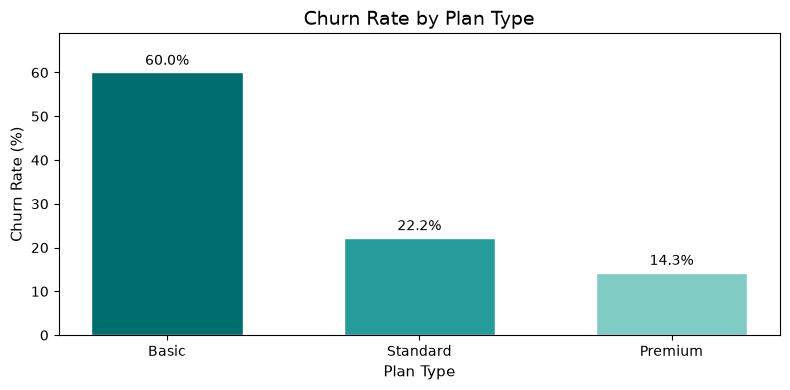

In [61]:
# 4.2 Churn by Plan Type

churn_plan = (
    df_visual.groupby('plan_type')['churn_flag']
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

# Different shades of teal
colors = ['#006D6F', '#269C9A', '#80CBC4']

plt.figure(figsize=(8, 4))

bars = plt.bar(
    churn_plan.index,
    churn_plan.values,
    color=colors,
    width=0.6,
    edgecolor='white',
    linewidth=1
)

plt.title('Churn Rate by Plan Type', fontsize=14)
plt.xlabel('Plan Type', fontsize=11)
plt.ylabel('Churn Rate (%)', fontsize=11)

plt.ylim(0, churn_plan.max() * 1.15)

# Percentage labels
for bar, value in zip(bars, churn_plan.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{value:.1f}%',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.tight_layout()
plt.show()

#### 7.3 churn by state

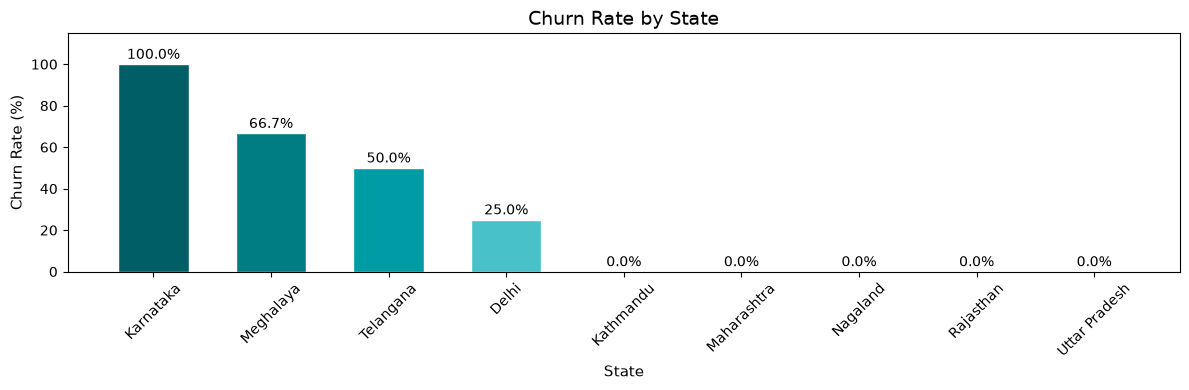

In [62]:
# 4.3 Churn by State

churn_state = (
    df_visual.groupby('state')['churn_flag']
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

# Different shades of teal
colors = ['#005F66', '#007C83', '#009CA6', '#48C1C8']

plt.figure(figsize=(12, 4))

bars = plt.bar(
    churn_state.index,
    churn_state.values,
    color=colors,
    width=0.6,
    edgecolor='white',
    linewidth=1
)

plt.title('Churn Rate by State', fontsize=14)
plt.xlabel('State', fontsize=11)
plt.ylabel('Churn Rate (%)', fontsize=11)

plt.ylim(0, churn_state.max() * 1.15)

# Percentage labels
for bar, value in zip(bars, churn_state.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{value:.1f}%',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8. Visualization using Seaborn 

#### 8.1 Heatmap

In [63]:
#Encoding - convert string to numeric value so that we can find correlation between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk'],
      dtype='str')

In [64]:
df_visual.dtypes

customerid                            str
subscription_start_date    datetime64[us]
subscription_type                     str
renewal_date               datetime64[us]
plan_type                             str
contract_type                         str
cancellation_date          datetime64[us]
cancellation_reason                   str
monthly_charges                   float64
cltv                                int64
churn_score                         int64
churn_flag                          int64
customer name                         str
country                               str
state                                 str
gender                                str
dob                        datetime64[us]
complaint_date             datetime64[us]
escalations                         int64
csat_score                        float64
complaint_count                   float64
tenure_days                       float64
churn_risk                            str
dtype: object

In [65]:
# remove warnings
import warnings
warnings.filterwarnings("ignore")

In [66]:
#encoding - based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

order_mappings = {
    'plan_type' : ['Basic', 'Standard', 'Premium'],
    'contract_type' : ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high']
    }

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [67]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [68]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


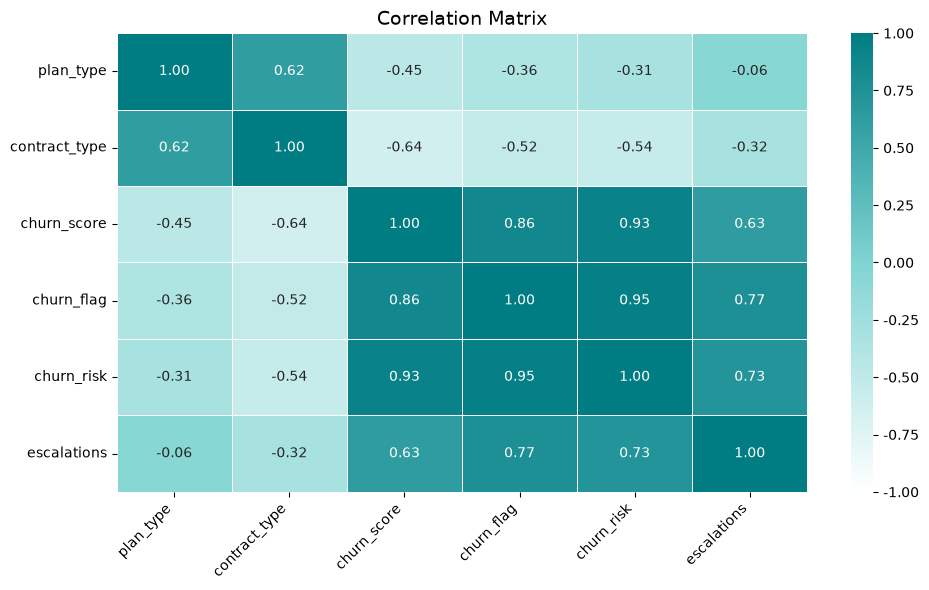

In [69]:
#Heatmap (Correlation Matrix)

correlation_matrix = df_encoded.corr()

from matplotlib.colors import LinearSegmentedColormap

teal_aqua = LinearSegmentedColormap.from_list(
    'teal_aqua',
    ['#FFFFFF', '#80D4D2', '#007C83'],
    N=256
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap=teal_aqua,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'format': '%.2f'}
)

plt.title('Correlation Matrix', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

#### 8.2 Pairplot: Visualize relationships between features

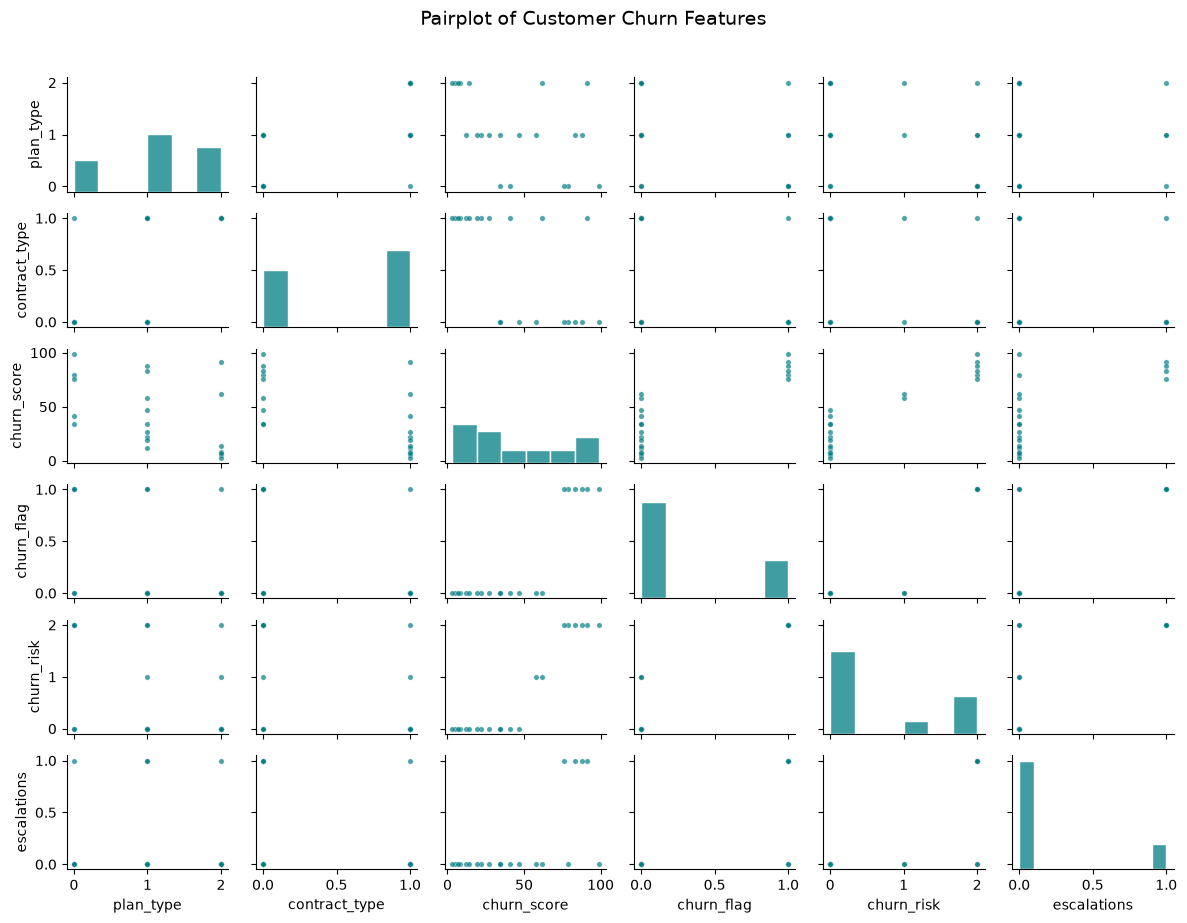

In [70]:
pairplot = sns.pairplot(
    df_encoded,
    diag_kind='hist',
    height=1.5,
    aspect=1.33,
    plot_kws={
        'color': '#007C83',  # Teal
        'alpha': 0.7,
        's': 15
    },
    diag_kws={
        'color': '#007C83',
        'edgecolor': 'white'
    }
)

pairplot.fig.suptitle(
    'Pairplot of Customer Churn Features',
    fontsize=14,
    y=1.02
)

pairplot.fig.tight_layout()
plt.show()

#### 8.3. Catplot / FacetGrid - Multi-dimensional comparison

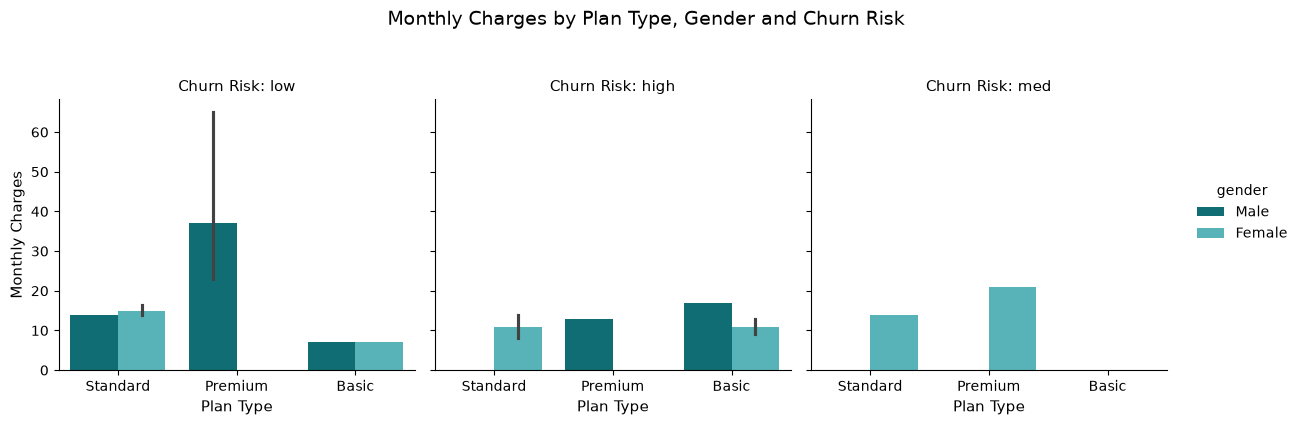

In [71]:
catplot = sns.catplot(
    data=df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk',
    kind='bar',
    palette=['#007C83', '#48C1C8'],
    height=4,
    aspect=1.0
)

catplot.fig.suptitle(
    'Monthly Charges by Plan Type, Gender and Churn Risk',
    fontsize=14,
    y=1.05
)

catplot.set_axis_labels('Plan Type', 'Monthly Charges', fontsize=11)
catplot.set_titles('Churn Risk: {col_name}', size=11)
catplot.set_xticklabels(rotation=0)
catplot.tight_layout()
plt.show()

### 9. Pivot Table: Churn Rate by Plan Type and Churn Risk

In [72]:
pd.pivot_table(
    df_visual, 
    index='plan_type',
    values='churn_flag',
    aggfunc = 'mean'
)

,churn_flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222


In [73]:
# pivot table using multiple cols and agg type

pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges', 'customerid', 'churn_flag'],
    aggfunc = {
        'monthly_charges' : 'sum',
        'customerid' : 'nunique',
        'churn_flag' : 'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


### 10. Key Takeaways: What Makes Customers Stay? 

Every customer who leaves has a story. Our data gives us a few clues about where those stories might begin.

- The Basic plan is waving the biggest red flag. With a 60% churn rate, it has the highest share of customers leaving. Could the plan be missing something customers need?

- Premium customers seem to have a stronger reason to stay. Their churn rate is just 14.29%, the lowest among the three plans. What makes this experience different?

- Standard customers fall somewhere in between. A 22.22% churn rate puts this plan between Basic and Premium, offering another piece of the retention puzzle.

- The numbers reveal where to look, not the whole answer. Plan type and churn rates show a pattern, but understanding why customers leave will take a closer look at their experiences and needs.

**The takeaway:** Customer churn isn't just a number to report. It's a signal to ask better questions, understand customer needs, and find opportunities to make staying worthwhile.